# Лабораторийн ажил: IoT агаарын чанарын өгөгдөлд AI ашиглан гаж утга илрүүлэх

**Сэдэв:** Rule-based detection + Isolation Forest  
**Хугацаа:** 150 минут  
**Орчин:** Google Colab / Jupyter Notebook  

Энэ notebook нь:
1. 7 хоногийн synthetic IoT dataset үүсгэнэ;
2. Data quality шалгана;
3. PM2.5, CO₂, температур, чийгшлийг дүрслэнэ;
4. Босго утгад суурилсан anomaly detection хийнэ;
5. Isolation Forest ашиглан unsupervised anomaly detection хийнэ;
6. Known label байвал confusion matrix, precision, recall, F1-score тооцно;
7. Боловсруулсан CSV болон зургуудыг хадгална.

> **Анхаарах:** Дасгалын threshold-үүд нь сургалтын зориулалттай. Албан ёсны эрүүл мэндийн стандарт гэж үзэхгүй.

## 1. Онолын товч үндэс

**Anomaly** гэдэг нь өгөгдлийн хэвийн төлөвөөс мэдэгдэхүйц зөрсөн ажиглалт юм.

- **Point anomaly:** нэг агшны огцом spike;
- **Contextual anomaly:** тухайн нөхцөлд хэвийн бус утга;
- **Collective anomaly:** дараалсан хэд хэдэн хэмжилт нийлээд хэвийн бус болох.

**Rule-based detection** нь тайлбарлахад хялбар боловч threshold-ийг хүн урьдчилан сонгоно.  
**Isolation Forest** нь хэвийн бус цэгүүд random partition-д цөөн алхмаар тусгаарлагддаг гэсэн санааг ашигладаг.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.ensemble import IsolationForest
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

np.random.seed(42)
OUTPUT_DIR = Path('/content/outputs') if Path('/content').exists() else Path('outputs')
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

FEATURES = ['PM2_5', 'CO2', 'Temperature', 'Humidity']

## 2. Dataset сонгох

`USE_REAL_CSV = False` хэвээр байвал notebook synthetic dataset үүсгэнэ.  
Бодит CSV ашиглах бол `USE_REAL_CSV = True` болгож, Colab-д файлаар upload хийнэ.

Бодит CSV-д шаардлагатай баганууд:

`Timestamp, PM2_5, CO2, Temperature, Humidity`

Сонголтоор `True_Anomaly` label байж болно.

In [2]:
USE_REAL_CSV = False
REAL_CSV_PATH = '/content/iot_air_quality.csv'


def generate_synthetic_data(n=168, seed=42):
    rng = np.random.default_rng(seed)
    timestamp = pd.date_range('2026-10-01 00:00', periods=n, freq='h')
    hour = np.arange(n) % 24

    pm25 = 28 + 10 * np.sin(2 * np.pi * (hour - 8) / 24) + rng.normal(0, 3, n)
    co2 = 650 + 120 * np.sin(2 * np.pi * (hour - 9) / 24) + rng.normal(0, 35, n)
    temperature = 18 + 5 * np.sin(2 * np.pi * (hour - 6) / 24) + rng.normal(0, 0.8, n)
    humidity = 45 - 8 * np.sin(2 * np.pi * (hour - 6) / 24) + rng.normal(0, 2, n)

    pm25 = np.clip(pm25, 3, None)
    co2 = np.clip(co2, 400, None)
    humidity = np.clip(humidity, 10, 95)

    true_anomaly = np.zeros(n, dtype=int)
    anomaly_type = np.array(['Normal'] * n, dtype=object)

    pm25[35] += 80
    pm25[36] += 100
    true_anomaly[[35, 36]] = 1
    anomaly_type[[35, 36]] = 'PM2.5 pollution event'

    pm25[91] += 65
    true_anomaly[91] = 1
    anomaly_type[91] = 'PM2.5 sensor/event spike'

    co2[120] += 900
    co2[121] += 1100
    true_anomaly[[120, 121]] = 1
    anomaly_type[[120, 121]] = 'CO2 ventilation/occupancy event'

    temperature[150] += 18
    true_anomaly[150] = 1
    anomaly_type[150] = 'Temperature sensor fault'

    humidity[151] = 92
    true_anomaly[151] = 1
    anomaly_type[151] = 'Humidity sensor fault'

    return pd.DataFrame({
        'Timestamp': timestamp,
        'PM2_5': pm25,
        'CO2': co2,
        'Temperature': temperature,
        'Humidity': humidity,
        'True_Anomaly': true_anomaly,
        'Anomaly_Type': anomaly_type,
    })


if USE_REAL_CSV:
    df = pd.read_csv(REAL_CSV_PATH)
    df['Timestamp'] = pd.to_datetime(df['Timestamp'], errors='coerce')
else:
    df = generate_synthetic_data()

print(df.shape)
df.head()

(168, 7)


,Timestamp,PM2_5,CO2,Temperature,Humidity,True_Anomaly,Anomaly_Type
0,2026-10-01 00:00:00,20.253897,559.664860,12.463088,47.070942,0,Normal
1,2026-10-01 01:00:00,15.220789,544.650263,13.419978,51.640416,0,Normal
2,2026-10-01 02:00:00,20.251354,511.171332,14.594123,56.769033,0,Normal
3,2026-10-01 03:00:00,21.162436,545.612527,14.951475,51.526623,0,Normal
4,2026-10-01 04:00:00,13.486640,518.164479,13.666968,47.880855,0,Normal


## 3. Data quality шалгах

- Timestamp зөв datetime болсон эсэх;
- Missing value;
- Duplicate row;
- Sensor field numeric эсэх;
- Timestamp дарааллаар эрэмбэлэгдсэн эсэхийг шалгана.

In [3]:
df['Timestamp'] = pd.to_datetime(df['Timestamp'], errors='coerce')
df = df.drop_duplicates().sort_values('Timestamp').reset_index(drop=True)

for column in FEATURES:
    df[column] = pd.to_numeric(df[column], errors='coerce')
    df[column] = df[column].interpolate(limit_direction='both')

print('Missing values:')
print(df.isnull().sum())

df = df.dropna(subset=['Timestamp', *FEATURES]).reset_index(drop=True)
print('Clean shape:', df.shape)
df[FEATURES].describe().round(2)

Missing values:
Timestamp       0
PM2_5           0
CO2             0
Temperature     0
Humidity        0
True_Anomaly    0
Anomaly_Type    0
dtype: int64
Clean shape: (168, 7)


,PM2_5,CO2,Temperature,Humidity
count,168.00,168.00,168.00,168.00
mean,29.30,662.74,18.10,45.07
std,14.19,134.10,3.97,7.19
min,13.49,456.24,11.41,33.28
25%,21.40,571.43,14.66,39.60
50%,27.88,656.10,17.89,44.53
75%,35.02,732.37,21.79,50.32
max,136.32,1642.45,35.38,92.00


## 4. Time-series visualization

Spike нэг удаа гарсан уу, эсвэл хэдэн цаг дараалан үргэлжилсэн үү гэдгийг plot-оос ажиглана.

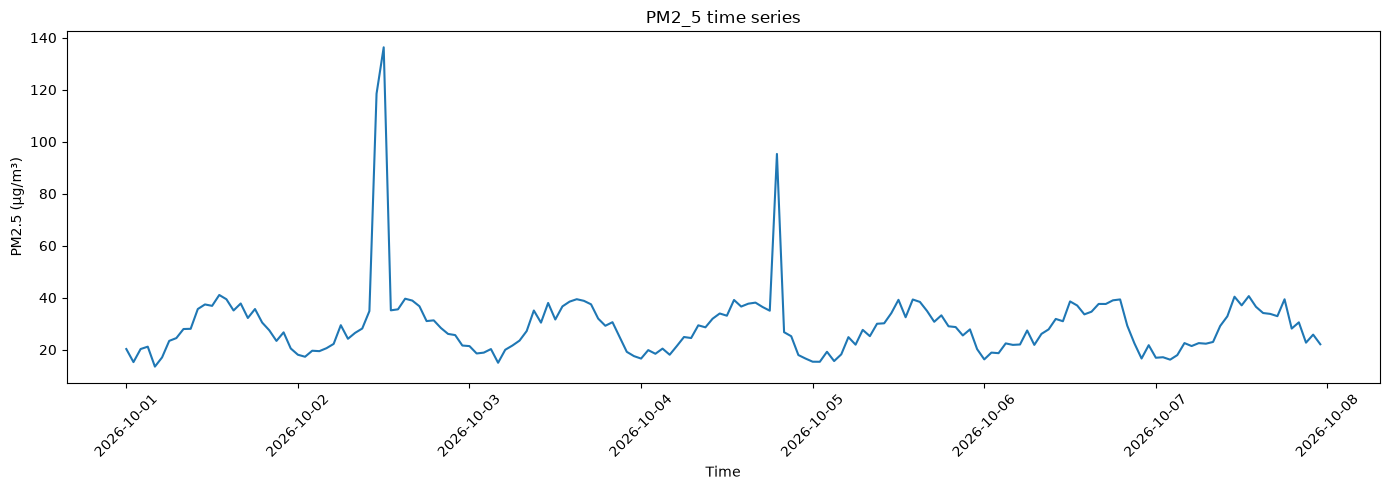

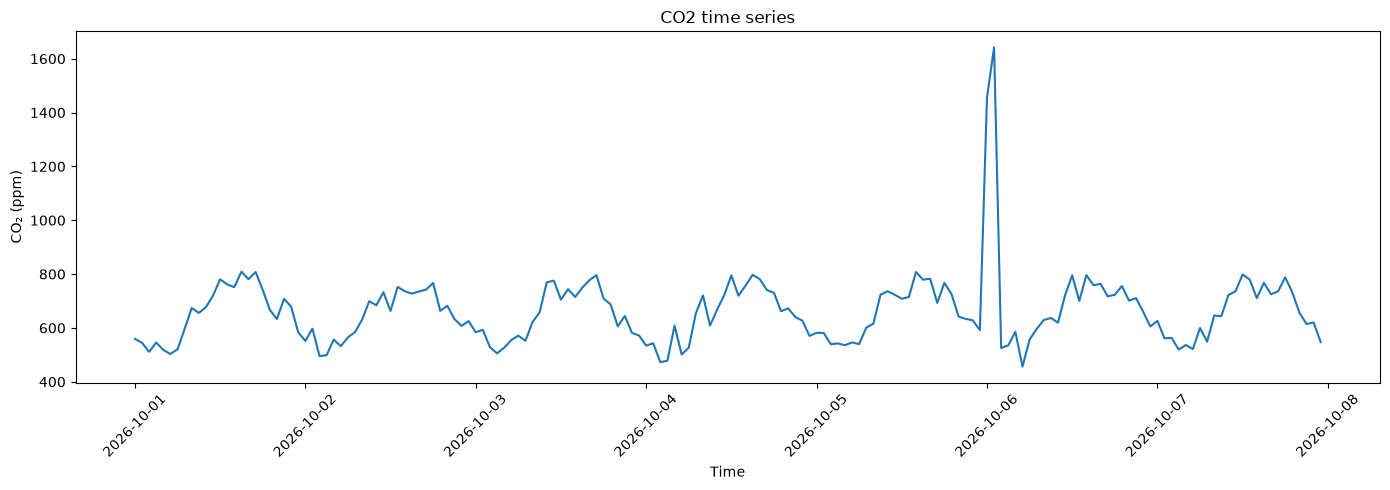

In [4]:
def plot_series(dataframe, variable, ylabel):
    plt.figure(figsize=(14, 5))
    plt.plot(dataframe['Timestamp'], dataframe[variable])
    plt.xlabel('Time')
    plt.ylabel(ylabel)
    plt.title(f'{variable} time series')
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / f'{variable.lower()}_timeseries.png', dpi=150)
    plt.show()

plot_series(df, 'PM2_5', 'PM2.5 (µg/m³)')
plot_series(df, 'CO2', 'CO₂ (ppm)')

## 5. Rule-based anomaly detection

Доорх threshold-үүд нь зөвхөн сургалтын жишээ. Бодит системд sensor type, орчны стандарт, calibration болон байгууллагын policy-д тохируулна.

In [5]:
PM25_THRESHOLD = 75.0
CO2_THRESHOLD = 1200.0
TEMP_MIN, TEMP_MAX = 5.0, 30.0
HUMIDITY_MIN, HUMIDITY_MAX = 20.0, 70.0


df['Rule_Anomaly'] = (
    (df['PM2_5'] > PM25_THRESHOLD)
    | (df['CO2'] > CO2_THRESHOLD)
    | (df['Temperature'] < TEMP_MIN)
    | (df['Temperature'] > TEMP_MAX)
    | (df['Humidity'] < HUMIDITY_MIN)
    | (df['Humidity'] > HUMIDITY_MAX)
).astype(int)

print('Rule-based anomaly count:', int(df['Rule_Anomaly'].sum()))
df[df['Rule_Anomaly'] == 1][['Timestamp', *FEATURES, 'Rule_Anomaly']]

Rule-based anomaly count: 7


,Timestamp,PM2_5,CO2,Temperature,Humidity,Rule_Anomaly
35,2026-10-02 11:00:00,118.457985,732.537858,23.892798,35.699462,1
36,2026-10-02 12:00:00,136.318412,663.096790,23.685435,33.627064,1
91,2026-10-04 19:00:00,95.292734,661.878647,18.082521,46.223339,1
120,2026-10-06 00:00:00,16.269253,1454.921195,13.860992,53.942273,1
121,2026-10-06 01:00:00,18.878569,1642.454862,12.493842,51.660502,1
150,2026-10-07 06:00:00,22.524095,599.782624,35.376414,46.174518,1
151,2026-10-07 07:00:00,22.304848,548.759373,19.638336,92.000000,1


## 6. Isolation Forest

`StandardScaler` нь дөрвөн feature-ийг ойролцоо scale-д оруулна.  
`contamination=0.05` гэдэг нь dataset-ийн ойролцоогоор 5%-ийг anomaly гэж үзэх таамаг юм.

Isolation Forest output:
- `1` = normal
- `-1` = anomaly

In [6]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(df[FEATURES])

model = IsolationForest(
    n_estimators=200,
    contamination=0.05,
    random_state=42
)

prediction = model.fit_predict(X_scaled)
df['IF_Prediction'] = prediction
df['IF_Anomaly'] = (prediction == -1).astype(int)
df['Anomaly_Score'] = -model.decision_function(X_scaled)

print('Isolation Forest anomaly count:', int(df['IF_Anomaly'].sum()))
df[df['IF_Anomaly'] == 1][['Timestamp', *FEATURES, 'Anomaly_Score']].sort_values('Anomaly_Score', ascending=False)

Isolation Forest anomaly count: 9


,Timestamp,PM2_5,CO2,Temperature,Humidity,Anomaly_Score
36,2026-10-02 12:00:00,136.318412,663.096790,23.685435,33.627064,0.204823
121,2026-10-06 01:00:00,18.878569,1642.454862,12.493842,51.660502,0.202530
151,2026-10-07 07:00:00,22.304848,548.759373,19.638336,92.000000,0.196204
120,2026-10-06 00:00:00,16.269253,1454.921195,13.860992,53.942273,0.174267
150,2026-10-07 06:00:00,22.524095,599.782624,35.376414,46.174518,0.174132
35,2026-10-02 11:00:00,118.457985,732.537858,23.892798,35.699462,0.154256
91,2026-10-04 19:00:00,95.292734,661.878647,18.082521,46.223339,0.142737
125,2026-10-06 05:00:00,21.999545,456.243906,16.039210,42.244992,0.011972
72,2026-10-04 00:00:00,16.581389,534.457059,11.405552,55.672372,0.008124


## 7. AI илрүүлсэн anomaly-г дүрслэх

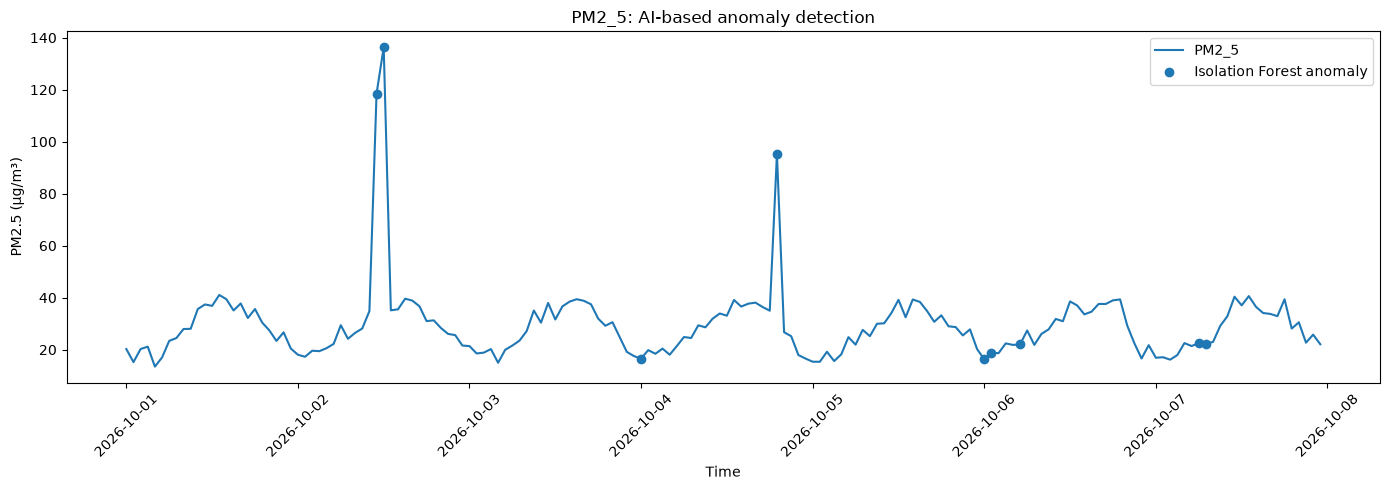

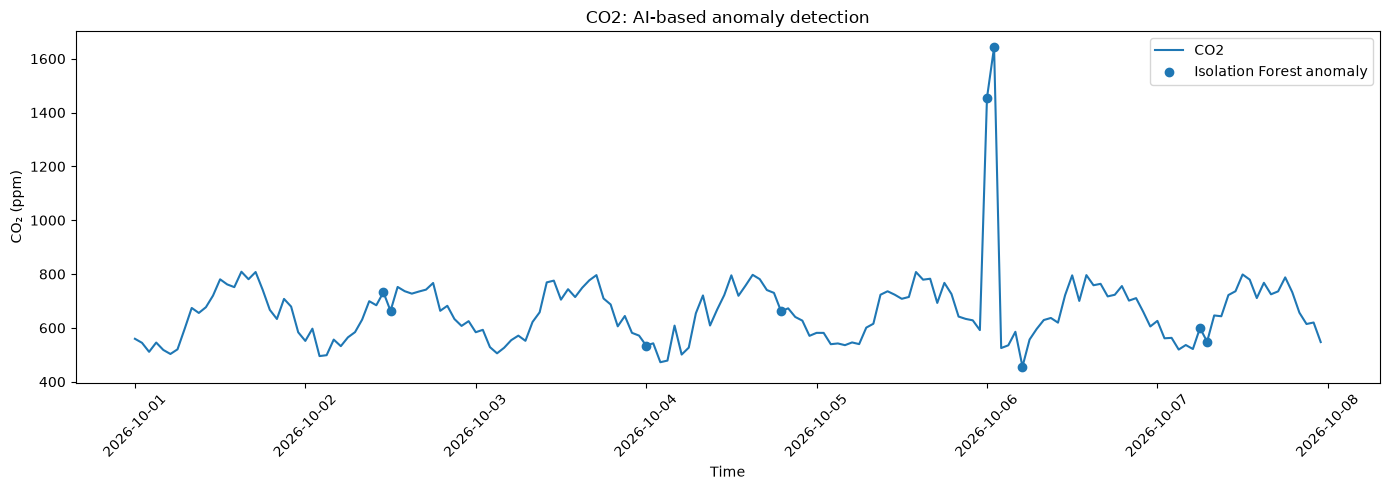

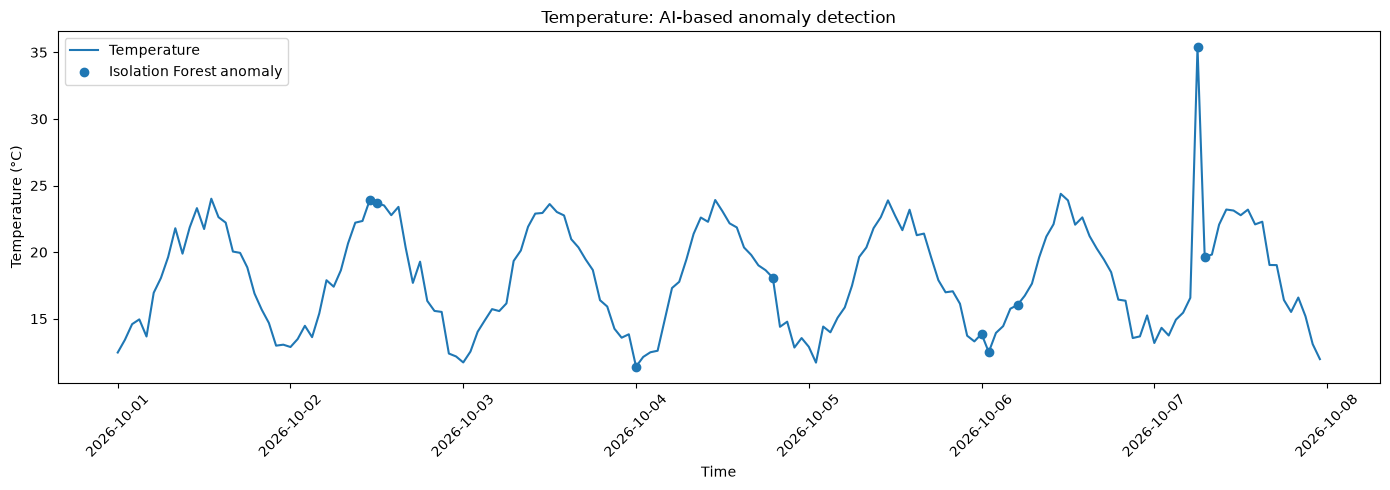

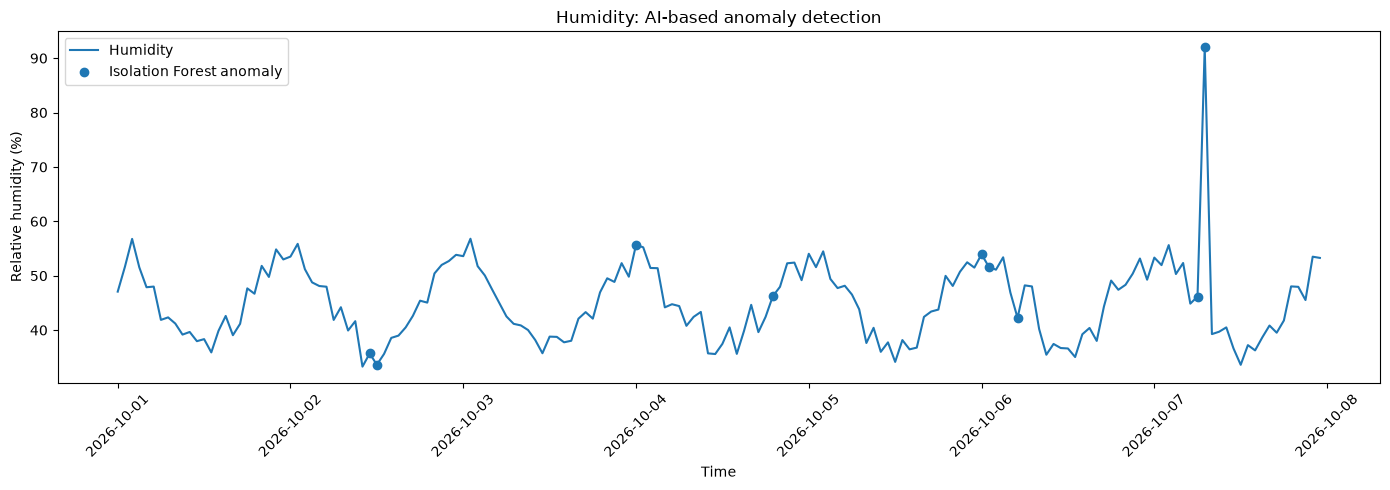

In [7]:
def plot_ai_anomalies(dataframe, variable, ylabel):
    anomaly_df = dataframe[dataframe['IF_Anomaly'] == 1]
    plt.figure(figsize=(14, 5))
    plt.plot(dataframe['Timestamp'], dataframe[variable], label=variable)
    plt.scatter(anomaly_df['Timestamp'], anomaly_df[variable], label='Isolation Forest anomaly')
    plt.xlabel('Time')
    plt.ylabel(ylabel)
    plt.title(f'{variable}: AI-based anomaly detection')
    plt.legend()
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / f'{variable.lower()}_anomalies.png', dpi=150)
    plt.show()

plot_ai_anomalies(df, 'PM2_5', 'PM2.5 (µg/m³)')
plot_ai_anomalies(df, 'CO2', 'CO₂ (ppm)')
plot_ai_anomalies(df, 'Temperature', 'Temperature (°C)')
plot_ai_anomalies(df, 'Humidity', 'Relative humidity (%)')


## 8. Model evaluation

`True_Anomaly` багана байгаа үед:
- **Precision:** model anomaly гэж хэлсэн цэгүүдээс хэд нь үнэхээр anomaly байсан бэ?
- **Recall:** бодит anomaly-уудаас хэдийг model олсон бэ?
- **F1-score:** precision ба recall-ийн тэнцвэр;
- **False positive:** хэвийн утгыг буруу anomaly гэж тэмдэглэх;
- **False negative:** бодит anomaly-г алдах.

              precision    recall  f1-score   support

           0       1.00      0.99      0.99       161
           1       0.78      1.00      0.88         7

    accuracy                           0.99       168
   macro avg       0.89      0.99      0.93       168
weighted avg       0.99      0.99      0.99       168

[[159   2]
 [  0   7]]


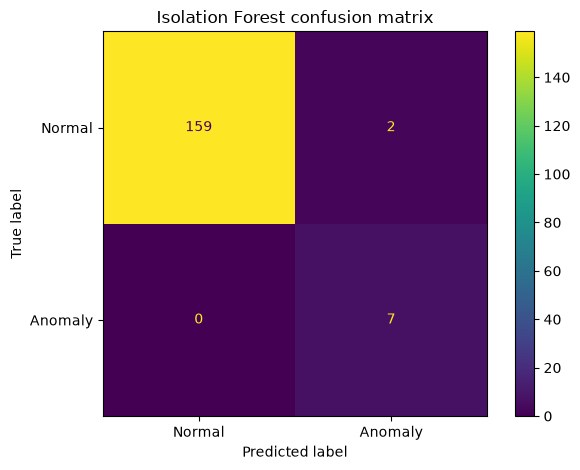

In [8]:
if 'True_Anomaly' in df.columns:
    y_true = df['True_Anomaly'].astype(int)
    y_pred = df['IF_Anomaly'].astype(int)

    print(classification_report(y_true, y_pred, zero_division=0))
    matrix = confusion_matrix(y_true, y_pred)
    print(matrix)

    ConfusionMatrixDisplay(
        confusion_matrix=matrix,
        display_labels=['Normal', 'Anomaly']
    ).plot()
    plt.title('Isolation Forest confusion matrix')
    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / 'confusion_matrix.png', dpi=150)
    plt.show()
else:
    print('True_Anomaly label алга. Supervised evaluation алгаслаа.')

## 9. Аргуудыг харьцуулах ба тайлбарлах

Rule-based болон Isolation Forest-ийн илрүүлсэн цэгүүдийг харьцуулна. Model output бүрийг шууд “бохирдол” гэж үзэхгүй. Sensor fault, calibration, occupancy, ventilation, гадна орчны нөлөө зэрэг нэмэлт context шаардлагатай.

Rule-based          7
Isolation Forest    9
dtype: int64


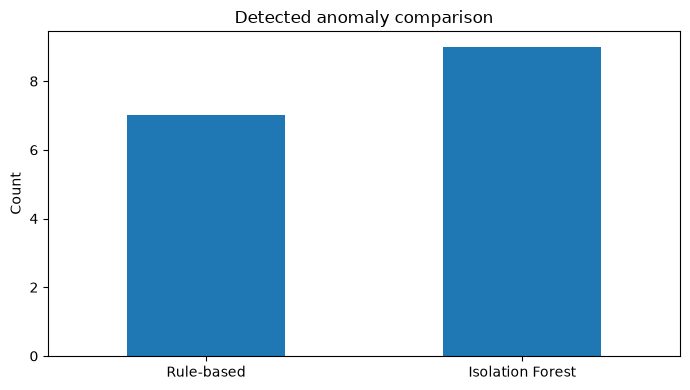

,Timestamp,PM2_5,CO2,Temperature,Humidity,True_Anomaly,Anomaly_Type,Rule_Anomaly,IF_Anomaly,Anomaly_Score
35,2026-10-02 11:00:00,118.46,732.54,23.89,35.70,1,PM2.5 pollution event,1,1,0.15
36,2026-10-02 12:00:00,136.32,663.10,23.69,33.63,1,PM2.5 pollution event,1,1,0.20
72,2026-10-04 00:00:00,16.58,534.46,11.41,55.67,0,Normal,0,1,0.01
91,2026-10-04 19:00:00,95.29,661.88,18.08,46.22,1,PM2.5 sensor/event spike,1,1,0.14
120,2026-10-06 00:00:00,16.27,1454.92,13.86,53.94,1,CO2 ventilation/occupancy event,1,1,0.17
121,2026-10-06 01:00:00,18.88,1642.45,12.49,51.66,1,CO2 ventilation/occupancy event,1,1,0.20
125,2026-10-06 05:00:00,22.00,456.24,16.04,42.24,0,Normal,0,1,0.01
150,2026-10-07 06:00:00,22.52,599.78,35.38,46.17,1,Temperature sensor fault,1,1,0.17
151,2026-10-07 07:00:00,22.30,548.76,19.64,92.00,1,Humidity sensor fault,1,1,0.20


In [9]:
comparison = pd.Series({
    'Rule-based': int(df['Rule_Anomaly'].sum()),
    'Isolation Forest': int(df['IF_Anomaly'].sum()),
})

print(comparison)
comparison.plot(kind='bar', figsize=(7, 4), title='Detected anomaly comparison')
plt.ylabel('Count')
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'method_comparison.png', dpi=150)
plt.show()
flagged = df[(df['Rule_Anomaly'] == 1) | (df['IF_Anomaly'] == 1) | (df['True_Anomaly'] == 1)]
flagged[['Timestamp', *FEATURES, 'True_Anomaly', 'Anomaly_Type', 'Rule_Anomaly', 'IF_Anomaly', 'Anomaly_Score']].round(dict.fromkeys([*FEATURES, 'Anomaly_Score'], 2))


## 10. Файл хадгалах

Дараах файлууд `/content/outputs` folder-д үүснэ:
- `iot_air_quality_analyzed.csv`
- `detected_anomalies.csv`
- `descriptive_statistics.csv`

In [10]:
df.to_csv(OUTPUT_DIR / 'iot_air_quality_analyzed.csv', index=False)
df[df['IF_Anomaly'] == 1].to_csv(OUTPUT_DIR / 'detected_anomalies.csv', index=False)
df[FEATURES].describe().round(3).to_csv(OUTPUT_DIR / 'descriptive_statistics.csv')

print('Saved to:', OUTPUT_DIR)
print(list(OUTPUT_DIR.iterdir()))

Saved to: outputs
[PosixPath('outputs/confusion_matrix.png'), PosixPath('outputs/temperature_anomalies.png'), PosixPath('outputs/method_comparison.png'), PosixPath('outputs/co2_timeseries.png'), PosixPath('outputs/detected_anomalies.csv'), PosixPath('outputs/humidity_anomalies.png'), PosixPath('outputs/pm2_5_timeseries.png'), PosixPath('outputs/pm2_5_anomalies.png'), PosixPath('outputs/iot_air_quality_analyzed.csv'), PosixPath('outputs/descriptive_statistics.csv'), PosixPath('outputs/co2_anomalies.png')]


## 11. Тайлангийн богино даалгавар

1. Dataset-ийн бүтэц, sampling interval-ийг тайлбарла.
2. Rule-based ба Isolation Forest-ийн anomaly count-ийг харьцуул.
3. False positive/false negative-ийн аль нь агаарын чанарын мониторингод илүү ноцтойг үндэслэ.
4. Илэрсэн anomaly бүрийн боломжит 2 тайлбар өг: бодит event эсвэл sensor fault.
5. 3–5 sustainability recommendation гарга.
6. Model limitation, uncertainty, data-governance шаардлагыг бич.